In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

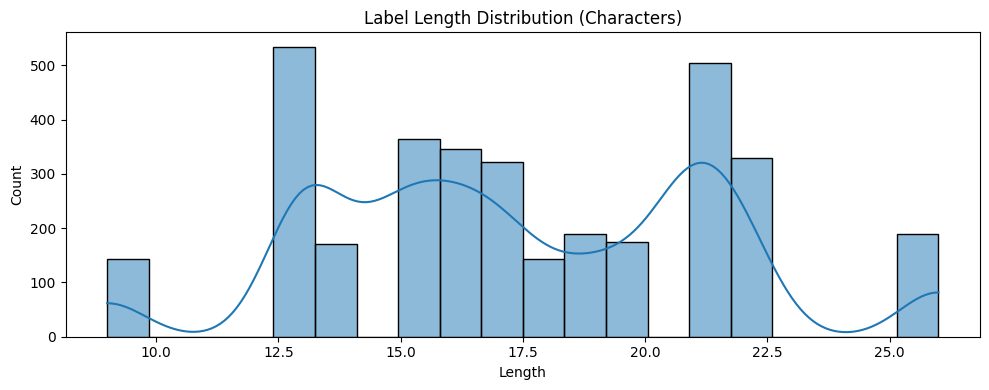

In [2]:
# Load birds.csv
df = pd.read_csv("../data/birds.csv")

# 1. Label complexity (length & word count)
df["label_length"] = df["labels"].apply(len)
df["label_word_count"] = df["labels"].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 4))
sns.histplot(df["label_length"], bins=20, kde=True)
plt.title("Label Length Distribution (Characters)")
plt.xlabel("Length")
plt.tight_layout()
plt.savefig("eda_label_length_distribution.png")
plt.show()


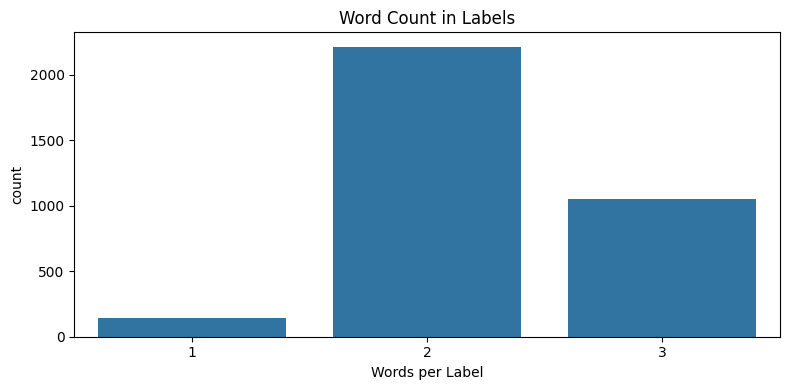

In [3]:

plt.figure(figsize=(8, 4))
sns.countplot(x="label_word_count", data=df)
plt.title("Word Count in Labels")
plt.xlabel("Words per Label")
plt.tight_layout()
plt.savefig("eda_word_count_labels.png")
plt.show()



In [4]:
# 2. Extract genus from scientific label
df["genus"] = df["scientific label"].apply(lambda x: x.split()[0] if isinstance(x, str) and len(x.split()) > 1 else "Unknown")

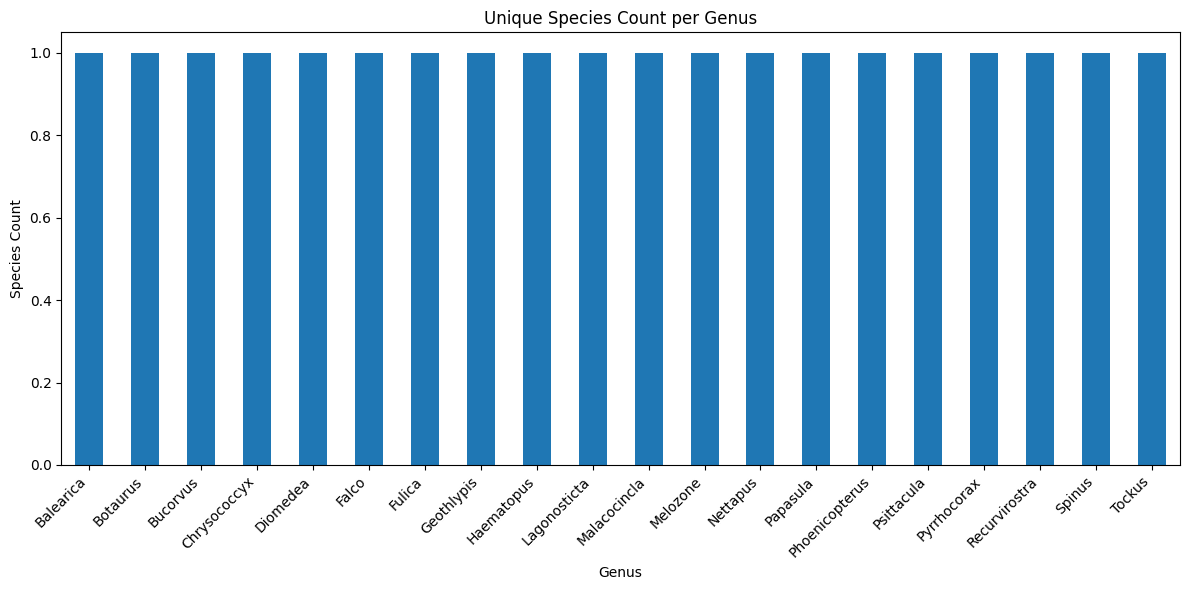

In [5]:
# 3. Plot genus distribution (unique species per genus)
genus_counts = df.groupby("genus")["labels"].nunique().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
genus_counts.plot(kind='bar')
plt.title("Unique Species Count per Genus")
plt.ylabel("Species Count")
plt.xlabel("Genus")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("eda_species_per_genus.png")
plt.show()


In [6]:
# Optional: Save enriched CSV with genus
df.to_csv("./birds_with_genus.csv", index=False)